# Week 9 — text analysis

How do preprocessing decisions change what we can count and interpret in a text?

## Setup

Extract the download and keep its `data` folder beside this notebook. In Colab,
the supplied file locator downloads missing teaching files from GitHub automatically.
Run the two setup cells, then work through the examples in
order. Keep the original text and source identifiers alongside derived measures;
`data/README.md` documents the sources and counting rules.

In [1]:
# PROVIDED ENVIRONMENT CHECK: run before teaching.
from pathlib import Path
import importlib.util
import subprocess
import sys
for package, requirement in (("pandas", "pandas"), ("matplotlib", "matplotlib"), ("spacy", "spacy"),
                             ("scipy", "scipy"), ("vaderSentiment", "vaderSentiment==3.3.2")):
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", requirement])
if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl"])
# Imports, data reads and model loading are shown explicitly in the stops.

In [ ]:
# PROVIDED FILE LOCATOR: use local teaching files or download them from GitHub.
from pathlib import Path
from urllib.request import urlopen
def teaching_file(name):
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent / "data" / name,
                          parent / "weeks/week-09/data" / name,
                          parent / "worksheets/week-09/data" / name, parent / name):
            if candidate.is_file():
                return candidate
    url = ("https://raw.githubusercontent.com/markjhill/7AAVBCS5-data/main/"
           "worksheets/week-09/data/" + name)
    print(f"Downloading {name} from the module GitHub repository...")
    with urlopen(url, timeout=60) as response:
        content = response.read()
    target = Path.cwd() / "data" / name
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_bytes(content)
    return target

## Jump to a demonstration

| Stop | Slide | Demonstration | Action |
|---|---|---|---|
| 01 | 9 | Introducing spaCy I | prepared |
| 02 | 10 | Introducing spaCy II | prepared |
| 03 | 13 | Tokenisation in Python | write-live |
| 04 | 14 | Inspect one token | prepared |
| 05 | 15 | Visit each token with a for loop | prepared |
| 06 | 20 | Pre-processing: punctuation removal | write-live |
| 07 | 22 | Lower-casing in Python | write-live |
| 08 | 23 | Pre-processing: stop-word removal | edit-live |
| 09 | 24 | Pre-processing: spelling standardisation | edit-live |
| 10 | 26 | Collect token information into rows | prepared |
| 11 | 27 | Turn the collected rows into a DataFrame | prepared |
| 12 | 30 | Lemmatisation changes the representation | prepared |
| 13 | 31 | Now with stopwords removed | prepared |
| 14 | 33 | Morphological tagging | prepared |
| 15 | 35 | Part-of-speech (POS) tagging | prepared |
| 16 | 43 | Technique 1 · Load the data | prepared |
| 17 | 44 | Technique 2 · Tokenise each article | prepared |
| 18 | 45 | Technique 2 · One row per token | prepared |
| 19 | 46 | Technique 2 · Choose the words to count | prepared |
| 20 | 47 | Technique 3 · Most frequent across the corpus | prepared |
| 21 | 48 | Technique 4 · Most frequent in one article | prepared |
| 22 | 49 | Technique 5 · Most frequent by group | prepared |
| 23 | 50 | Technique 6 · Top words as a proportion | prepared |
| 24 | 52 | Technique 7 · Score sentiment across the reviews | prepared |
| 25 | 53 | Technique 8 · Stars vs sentiment score | prepared |

# Part II: The NLP pipeline

## 01. Introducing spaCy I

**Slide 9 · prepared**

**spaCy is a Python library for working with human language.** It identifies
words and punctuation, and supplies information about them for text analysis.

spaCy provides the tools. We also load an **English language package** containing
language rules and models trained on example texts. We can use these without
training a model ourselves.

`import spacy` makes the library available. `spacy.load("en_core_web_sm")` loads
an installed English package: `en` = English, `core` = general linguistic features,
`web` = written web texts, `sm` = small. [Package details](https://spacy.io/models/en#en_core_web_sm).

We call the loaded processor `nlp`. `nlp(weather_text)` analyses our sentence;
`weather_doc` holds the text and results together. `type()` shows that this is a
spaCy `Doc`, rather than a string; `len()` counts its tokens, including punctuation.

In [3]:
import spacy
nlp = spacy.load("en_core_web_sm")
weather_text = ("This morning there were clouds in the sky. However, the weather improved in the afternoon!")
weather_doc = nlp(weather_text)
print(type(weather_text))
print(type(weather_doc))
print(len(weather_doc))

<class 'str'>
<class 'spacy.tokens.doc.Doc'>
18


## 02. Introducing spaCy II

**Slide 10 · prepared**

What's in a spaCy object? Lots!

In [4]:
import pandas as pd
weather_df = pd.DataFrame(weather_doc.to_json()["tokens"])
weather_df

,id,start,end,tag,pos,morph,lemma,dep,head
0,0,0,4,DT,DET,Number=Sing|PronType=Dem,this,det,1
1,1,5,12,NN,NOUN,Number=Sing,morning,npadvmod,3
2,2,13,18,EX,PRON,,there,expl,3
3,3,19,23,VBD,VERB,Mood=Ind|Tense=Past|VerbForm=Fin,be,ROOT,3
4,4,24,30,NNS,NOUN,Number=Plur,cloud,attr,3
5,5,31,33,IN,ADP,,in,prep,4
6,6,34,37,DT,DET,Definite=Def|PronType=Art,the,det,7
7,7,38,41,NN,NOUN,Number=Sing,sky,pobj,5
8,8,41,42,.,PUNCT,PunctType=Peri,.,punct,3
9,9,43,50,RB,ADV,,however,advmod,13


## 03. Tokenisation in Python

**Slide 13 · write-live**

spaCy has already tokenised our text. Here we inspect its token boundaries
and count occurrences and distinct forms in the short example.

spaCy treats `!` as a token. `len(token_doc)` counts occurrences; `pd.Series(token_texts).nunique()` counts distinct text forms, including punctuation.

**Note**: we're using a for loop here! More on these shortly.

In [5]:
import pandas as pd
text = "I go where I want to go!" # Note the ! and what it does to our counts
token_doc = nlp(text)
token_texts = []
for token in token_doc:
    token_texts.append(token.text)
print(token_texts)
print("Tokens:", len(token_doc))
print("Types:", pd.Series(token_texts).nunique())

['I', 'go', 'where', 'I', 'want', 'to', 'go', '!']
Tokens: 8
Types: 6


## 04. Inspect one token

**Slide 14 · prepared**

Each indexed item in a spaCy object (`Doc`) is a `Token`, along with a huge number of  attributes attached to it.

`weather_doc[0]` selects the first token; `weather_doc[-1]` selects the last.
`text` gives its text. The other attributes return `True` or `False`:
letters only, digits only, number-like, punctuation, or membership of a stop list.
More attributes include `lower_`, `is_space`, `like_url` and `like_email`:
[spaCy Token reference](https://spacy.io/api/token#attributes).

In [6]:
token = weather_doc[0]
print(type(token))
print("Text:", token.text)
print("Alphabetic:", token.is_alpha)
print("Digits:", token.is_digit)
print("Number-like:", token.like_num)
print("Punctuation:", token.is_punct)
print("Stopword:", token.is_stop)

<class 'spacy.tokens.token.Token'>
Text: This
Alphabetic: True
Digits: False
Number-like: False
Punctuation: False
Stopword: True


## 05. Visit each token with a for loop

**Slide 15 · prepared**

What is we want to look at more than one token? This is where loops can be useful.

Instead of writing a separate index for every position a `for` loop repeats the indented instruction for each item in the document.

`for token in weather_doc:` takes one token at a time from weather_doc and assigns it to `token`. The colon starts the loop body. Indentation puts `print(token.text)` inside the loop, so it runs once for each token. `token` is a variable name we choose.

In [7]:
for token in weather_doc:
    print(token.text)

This
morning
there
were
clouds
in
the
sky
.
However
,
the
weather
improved
in
the
afternoon
!


## 06. Pre-processing: punctuation removal

**Slide 20 · write-live**

Remove punctuation when it does not carry information needed for the research
question or method. spaCy has already identified punctuation tokens with
`token.is_punct`; we can choose which tokens to retain.

Punctuation can mark sentence boundaries, emphasis, and style. Keep it when those features matter (e.g., preserving apostrophes avoids erasing them from contractions such as "can't").


`for every_token_in_weather_doc in weather_doc:` visits one token at a time. The colon and indentation mark the instructions to repeat. `if not token.is_punct:` keeps tokens whose punctuation flag is `False`. `.append(token.text)` adds their text to the list; the unindented `print()` runs once, after the loop.

In [8]:
print(weather_doc)
print("")
print(f"Is the 8th token, '{weather_doc[7]}', punctuation? {weather_doc[7].is_punct}")
print(f"Is the 9th token, '{weather_doc[8]}', punctuation? {weather_doc[8].is_punct}")
print("")
words_without_punctuation = []
for every_token_in_weather_doc in weather_doc:   
    if not every_token_in_weather_doc.is_punct:
        words_without_punctuation.append(every_token_in_weather_doc.text)
print(words_without_punctuation)

This morning there were clouds in the sky. However, the weather improved in the afternoon!

Is the 8th token, 'sky', punctuation? False
Is the 9th token, '.', punctuation? True

['This', 'morning', 'there', 'were', 'clouds', 'in', 'the', 'sky', 'However', 'the', 'weather', 'improved', 'in', 'the', 'afternoon']


## 07. Lower-casing in Python

**Slide 22 · write-live**

`token.lower_` supplies a lowercase form alongside the original token text.

The first token is `This`; its lowercase form is `this`. The original text
remains available. Use the lowercase form when combining case serves the question.


`weather_doc[0]` selects the first token. `.text` gives its original form;
`.lower_` gives its lowercase form. These are attributes, so we do not add `()`.

In [9]:
token = weather_doc[0]
print(token.text)
print(token.lower_)

This
this


## 08. Pre-processing: stop-word removal

**Slide 23 · edit-live**

Stop-words are very common words, often function words. These include things like "and", "the", "this", "that", "a", etc.. They are **by far** the most common words in most (every?) language.

We often remove them so that we can focus a _thematic_ words. However, this could also also remove stylistic and grammatical evidence if important.

`token.is_stop` checks membership of spaCy's English stop list. `not` reverses
the test; `and` requires both tests to pass. This keeps tokens flagged as neither
stopwords nor punctuation. Tokenisation has already happened inside `nlp()`.

In [10]:
content_words = []
for token in weather_doc:
    if not token.is_stop and not token.is_punct:
        content_words.append(token.text)
print(content_words)

['morning', 'clouds', 'sky', 'weather', 'improved', 'afternoon']


## 09. Pre-processing: spelling standardisation

**Slide 24 · edit-live**

Variant spellings, typos, and elongated forms can, again, divide or inflate counts across different written forms: for example, `colour` and its mispelled variation `color`.

Domain-specific dictionaries and tools can help. Historical spelling, dialect
and informal language may be evidence, so preserve the original and justify the rule.

In [11]:
import re
variant_text = "colour and color"
standardised = re.sub(r"\bcolor\b", "colour", variant_text)
print(standardised)

colour and colour


## 10. Collect token information into rows

**Slide 26 · prepared**

Start with an empty list. For each token, create one dictionary and append it
to the list. Keep every token for now, including punctuation and stopwords.

`[]` creates an empty list. A dictionary pairs each column name with a value.
`weather_rows.append(row)` adds that dictionary to the list. Both indented
statements repeat; the unindented `print()` calls run after the loop finishes.

In [12]:
weather_rows = []
for token in weather_doc:
    row = {
        "text": token.text,
        "is_alpha": token.is_alpha,
        "is_digit": token.is_digit,
        "is_punct": token.is_punct,
        "is_stop": token.is_stop,
    }
    weather_rows.append(row)

print("Rows collected:", len(weather_rows))
print(weather_rows[0])

Rows collected: 18
{'text': 'This', 'is_alpha': True, 'is_digit': False, 'is_punct': False, 'is_stop': True}


## 11. Turn the collected rows into a DataFrame

**Slide 27 · prepared**

The loop has finished. pandas can now turn our list of dictionaries into a
familiar table: one row per token and one column per attribute we selected.

`pd.DataFrame(weather_rows)` uses the list as its input. Dictionary keys become
column names and their values fill the rows. `.head(6)` selects the first six
rows for display; it does not shorten the saved DataFrame.
`display(...)` shows the resulting table in the notebook or slides.

In [13]:
import pandas as pd
weather_tokens = pd.DataFrame(weather_rows)
display(weather_tokens.head(6))

,text,is_alpha,is_digit,is_punct,is_stop
0,This,True,False,False,True
1,morning,True,False,False,False
2,there,True,False,False,True
3,were,True,False,False,True
4,clouds,True,False,False,False
5,in,True,False,False,True


## 12. Lemmatisation changes the representation

**Slide 30 · prepared**

**Original:** “This morning there were clouds in the sky but the weather improved in the afternoon.”

`token.lemma_` gives spaCy's proposed base form as text. The loop displays each
original token beside its lemma. These results were produced when we ran
`nlp(weather_text)`; accessing them does not change the original sentence.

In [14]:
for token in weather_doc:
    print(token.text, "=", token.lemma_)

This = this
morning = morning
there = there
were = be
clouds = cloud
in = in
the = the
sky = sky
. = .
However = however
, = ,
the = the
weather = weather
improved = improve
in = in
the = the
afternoon = afternoon
! = !


## 13. Now with stopwords removed

**Slide 31 · prepared**

**Original:**

“This morning there were clouds in the sky but the weather improved in the afternoon.”

**Combine the lemma and stopword information:**

**Is there still meaning?** 

Combining lemmas and a stop-word filter keeps selected vocabulary while
removing tense, grammatical links, and the contrast marked by `but`.

I think many of us would struggle to decipher this.


![](images/odp/original-32-1.png){height=210 fig-alt="A bag labelled words, retained from the original lecture"}

In [15]:
lemmas = []
for token in weather_doc:
    if not token.is_stop and not token.is_punct:
        lemmas.append(token.lemma_)
print(lemmas)

['morning', 'cloud', 'sky', 'weather', 'improve', 'afternoon']


## 14. Morphological tagging

**Slide 33 · prepared**

Morphological annotation describes grammatical features such as tense, number, gender, case, or degree. It records information beyond the surface form.

- `walked` → verb, past tense
- `dogs` → noun, plural
- `better` → adjective, comparative (in an appropriate sentence)

Inspect two forms in our actual weather sentence:

`morph` contains the pipeline's _predicted_ features - this comes from the model we loaded at the start.

In [16]:
print(weather_doc[3].text, "is", weather_doc[3].morph)
print(weather_doc[4].text, "is", weather_doc[4].morph)

were is Mood=Ind|Tense=Past|VerbForm=Fin
clouds is Number=Plur


## 15. Part-of-speech (POS) tagging

**Slide 35 · prepared**

Assign a token its grammatical category according to its use in the sentence.
The same form can have different functions. E.g., `run` in “a 5k run” and “I run daily”.

POS needs the sentence to construct context. It doesn't assign an isolated word a permanent category.

In [17]:
noun_doc = nlp("I bought a book.")
verb_doc = nlp("I will book a ticket.")

print(noun_doc[3].text, noun_doc[3].pos_)
print(verb_doc[2].text, verb_doc[2].pos_)

book NOUN
book VERB


# Part III: Counting words

## 16. Technique 1 · Load the data

**Slide 43 · prepared**

Load a table of texts from a file. Your own data loads the same way — a column of a
CSV, or a text file.

`read_csv` loads any CSV; swap the path for your own file. Each row here is one
Wikipedia article, with its text, category and borough.

In [18]:
import pandas as pd
corpus = pd.read_csv(teaching_file("w09_corpus.csv.gz"))
display(corpus[["title", "category", "borough"]].head())
print("First article begins:", corpus["text"].iloc[0][:150])
# your own data loads the same way:
# corpus = pd.read_csv("my_reviews.csv")               # a CSV with a text column
# text   = open("my_notes.txt", encoding="utf-8").read()   # a single text file

,title,category,borough
0,100 Club,Music venue,Westminster
1,2 Willow Road,Museum,Camden
2,606 Club,Music venue,Kensington and Chelsea
3,7 Hammersmith Terrace,Museum,Hammersmith and Fulham
4,Adelphi Theatre,Theatre,Westminster


First article begins: The 100 Club is a music venue located at 100 Oxford Street, Westminster, England, where it has been hosting live music since 24 October 1942. It was o


## 17. Technique 2 · Tokenise each article

**Slide 44 · prepared**

Repeat the tokenisation for every article. Keep each article's tokens in a list.

`nlp.tokenizer(text)` splits one text into tokens. `list(doc)` puts its tokens in
a list; `.append()` adds that list to `article_tokens`.

In [19]:
article_tokens = []
for text in corpus["text"]:
    doc = nlp.tokenizer(text)
    article_tokens.append(list(doc))
corpus["token"] = article_tokens
display(corpus[["title", "token"]].head(2))

,title,token
0,100 Club,"[The, 100, Club, is, a, music, venue, located,..."
1,2 Willow Road,"[2, Willow, Road, is, part, of, a, terrace, of..."


## 18. Technique 2 · One row per token

**Slide 45 · prepared**

Unpack the lists so we can count tokens in a familiar table.

`.explode("token")` turns each item in a token list into a separate row.
The article's title and category are repeated alongside each token.

In [20]:
words = corpus.explode("token")
display(words[["title", "category", "token"]].head(6))

,title,category,token
0,100 Club,Music venue,The
0,100 Club,Music venue,100
0,100 Club,Music venue,Club
0,100 Club,Music venue,is
0,100 Club,Music venue,a
0,100 Club,Music venue,music


## 19. Technique 2 · Choose the words to count

**Slide 46 · prepared**

Keep alphabetic tokens that are not stop words. Count lowercase word forms.

`keep` collects a True/False decision for each row. `words[keep]` selects the
True rows. `token.lower_` supplies the lowercase form, not a lemma.

In [21]:
keep = []
word_text = []
for token in words["token"]:
    keep.append(token.is_alpha and not token.is_stop)
    word_text.append(token.lower_)
words["word"] = word_text
words = words[keep]
display(words[["title", "category", "word"]].head(6))

,title,category,word
0,100 Club,Music venue,club
0,100 Club,Music venue,music
0,100 Club,Music venue,venue
0,100 Club,Music venue,located
0,100 Club,Music venue,oxford
0,100 Club,Music venue,street


## 20. Technique 3 · Most frequent across the corpus

**Slide 47 · prepared**

Count the word column with `value_counts` — the same verb as counting one text.

`value_counts()` on the whole word column counts every word in the corpus.

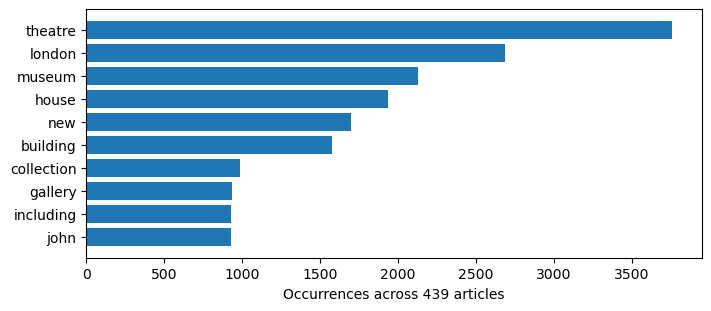

In [22]:
import matplotlib.pyplot as plt
top = words["word"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.barh(top.index, top.values)
ax.set_xlabel("Occurrences across 439 articles")
plt.show()

## 21. Technique 4 · Most frequent in one article

**Slide 48 · prepared**

Filter the same table to one article.

Filter the word table to one article's rows, then `value_counts`.

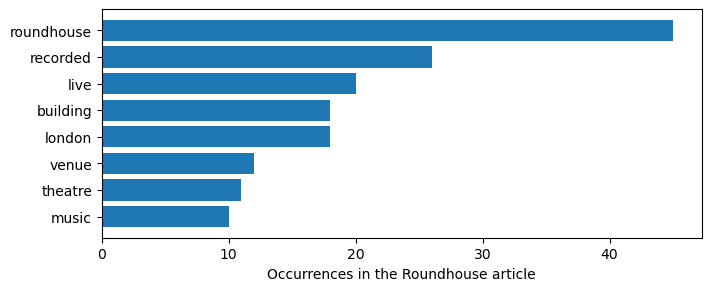

In [23]:
one_article = words[words["title"] == "Roundhouse (venue)"]
top = one_article["word"].value_counts().head(8).sort_values()
fig, ax = plt.subplots(figsize=(7, 2.8), layout="constrained")
ax.barh(top.index, top.values)
ax.set_xlabel("Occurrences in the Roundhouse article")
plt.show()

## 22. Technique 5 · Most frequent by group

**Slide 49 · prepared**

Count within museums, theatres and music venues, using the category column.

The category came in with the data, so we just filter and `value_counts` per group.

In [24]:
pd.DataFrame({
    category: words[words["category"] == category]["word"].value_counts().head(6).index
    for category in ["Museum", "Theatre", "Music venue"]})

,Museum,Theatre,Music venue
0,museum,theatre,london
1,house,starring,st
2,london,london,church
3,collection,new,stadium
4,gallery,directed,venue
5,building,building,new


## 23. Technique 6 · Top words as a proportion

**Slide 50 · prepared**

Counts favour the biggest group. A **share** — `value_counts(normalize=True)` — lets
us compare groups of different sizes.

`normalize=True` turns counts into shares, so a bigger group no longer looks bigger.

In [25]:
rows = []
for category in ["Museum", "Theatre", "Music venue"]:
    share = words[words["category"] == category]["word"].value_counts(normalize=True).head(4) * 100
    for word, percent in share.items():
        rows.append({"category": category, "word": word, "percent": round(percent, 2)})
pd.DataFrame(rows)

,category,word,percent
0,Museum,museum,1.44
1,Museum,house,0.89
2,Museum,london,0.80
3,Museum,collection,0.66
4,Theatre,theatre,3.13
5,Theatre,starring,0.79
6,Theatre,london,0.73
7,Theatre,new,0.64
8,Music venue,london,1.08
9,Music venue,st,0.80


# Part IV: Sentiment in reviews

## 24. Technique 7 · Score sentiment across the reviews

**Slide 52 · prepared**

**VADER** scores each text from −1 (negative) to +1 (positive). Apply it to every
review.

`.apply` runs the scorer on every review. We keep the original text — punctuation and
capitals change the score.

In [26]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
scorer = SentimentIntensityAnalyzer()
reviews = pd.read_csv(teaching_file("w09_review_scores.csv"))
reviews["score"] = reviews["review_text"].apply(
    lambda text: scorer.polarity_scores(text)["compound"])
display(reviews[["canonical_name", "rating", "score"]].head(6))

,canonical_name,rating,score
0,Royal Academy of Arts,1,0.2799
1,Royal Academy of Arts,1,0.7717
2,Royal Academy of Arts,1,0.8192
3,Royal Academy of Arts,5,0.9498
4,Royal Academy of Arts,5,0.8910
5,Royal Academy of Arts,5,0.4404


## 25. Technique 8 · Stars vs sentiment score

**Slide 53 · prepared**

Do our scores agree with the visitors' stars? Compare the mean score per star, and
test the correlation.

**The score rises with the rating, but the link is weak (r ≈ 0.22): stars and text sentiment agree only loosely.**


`pearsonr` returns the correlation and a p-value — a small p means the link is
unlikely to be chance, not that it is strong.

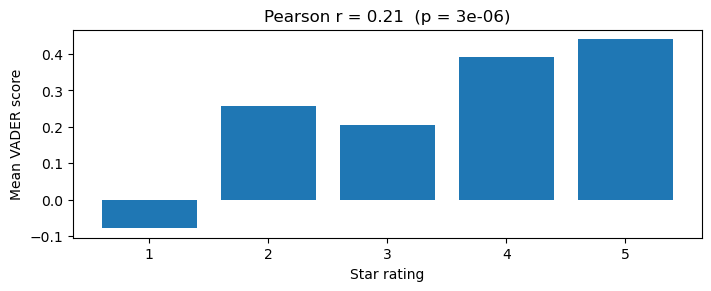

In [27]:
from scipy.stats import pearsonr
mean_by_star = reviews.groupby("rating")["score"].mean()
r, p = pearsonr(reviews["rating"], reviews["score"])
fig, ax = plt.subplots(figsize=(7, 2.8), layout="constrained")
ax.bar(mean_by_star.index.astype(str), mean_by_star.values)
ax.set_xlabel("Star rating")
ax.set_ylabel("Mean VADER score")
ax.set_title(f"Pearson r = {r:.2f}  (p = {p:.1g})")
plt.show()

# Explain a result

For a result we want to report, identify the source and counting unit, state the
preprocessing rule and denominator, and explain what the output supports. Retain
the passages needed to assess that interpretation.